# Flight Delay Prediction — Phase 1 (Machine Learning)

**Project 21:** Flight Delay Prediction via Gradient Boosting and Temporal Deep Learning

**Goal:** predict whether a flight will **arrive 15 or more minutes late**, using only information that is known
**before the flight departs**.

**Dataset:** Flights 2013 (`nycflights13`) — every flight that left a New York City airport (JFK, LGA, EWR) in 2013.

**Models (Phase 1):** Logistic Regression (baseline) and XGBoost.

### Contents
1. Load the data
2. Data quality checks
3. Exploratory Data Analysis (EDA)
4. Removing data leakage
5. Feature engineering
6. Train / validation / test split by date
7. Models: Logistic Regression and XGBoost
8. Evaluation and calibration
9. Conclusion

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nycflights13 import flights

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

Each row is one scheduled flight. The `flights` table has 19 columns: the date, scheduled and actual departure/arrival
times, the delays, carrier, flight number, plane tail number, origin, destination, air time and distance.

In [2]:
df = flights.copy()
print("Shape:", df.shape)
df.head()

Shape: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            336776 non-null  int64  
 1   month           336776 non-null  int64  
 2   day             336776 non-null  int64  
 3   dep_time        328521 non-null  float64
 4   sched_dep_time  336776 non-null  int64  
 5   dep_delay       328521 non-null  float64
 6   arr_time        328063 non-null  float64
 7   sched_arr_time  336776 non-null  int64  
 8   arr_delay       327346 non-null  float64
 9   carrier         336776 non-null  str    
 10  flight          336776 non-null  int64  
 11  tailnum         334264 non-null  str    
 12  origin          336776 non-null  str    
 13  dest            336776 non-null  str    
 14  air_time        327346 non-null  float64
 15  distance        336776 non-null  int64  
 16  hour            336776 non-null  int64  
 17  minute          33677

## 2. Data quality checks

We check for missing values and duplicate rows.

In [4]:
missing = df.isna().sum()
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())

dep_time     8255
dep_delay    8255
arr_time     8713
arr_delay    9430
tailnum      2512
air_time     9430
dtype: int64

Duplicate rows: 0


- About 8,255 flights have no `dep_time` — these flights were **cancelled**.
- About 9,430 flights have no `arr_delay` — cancelled flights plus a few **diverted** flights that never arrived at the planned destination.
- There are no duplicate rows.

Our target needs the arrival delay, so we **drop flights without an `arr_delay`** (cancelled/diverted flights are a
different problem). Missing `tailnum` values do not matter because we do not use that column.

In [5]:
df = df.dropna(subset=["arr_delay"]).copy()

# Target: 1 if the flight arrived 15+ minutes late (the US Department of Transportation definition of "delayed")
df["delayed"] = (df["arr_delay"] >= 15).astype(int)

# A proper date column, used for EDA, features and the date-based split
df["date"] = pd.to_datetime(df[["year", "month", "day"]])

print("Flights left:", len(df))
print("Delayed share:", round(df["delayed"].mean(), 3))

Flights left: 327346
Delayed share: 0.245


## 3. Exploratory Data Analysis

### 3.1 Target balance and the distribution of arrival delays

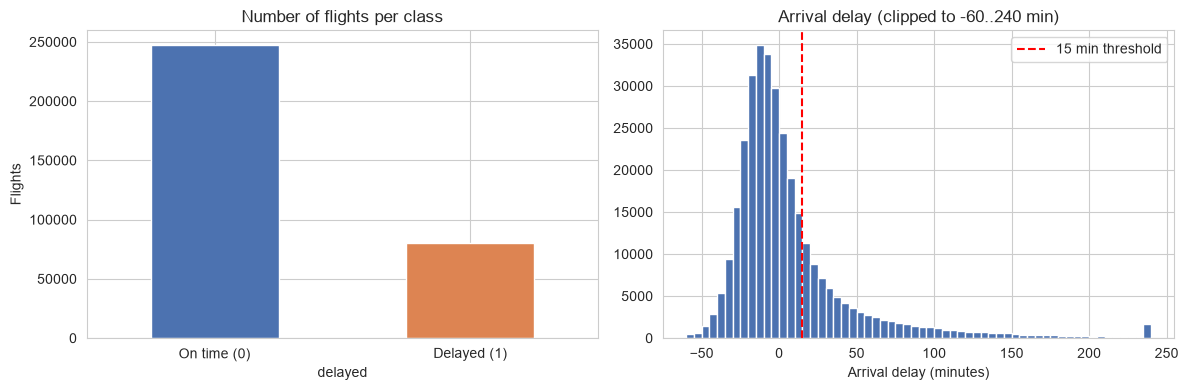

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["delayed"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_xticks([0, 1], ["On time (0)", "Delayed (1)"], rotation=0)
axes[0].set_title("Number of flights per class")
axes[0].set_ylabel("Flights")

axes[1].hist(df["arr_delay"].clip(-60, 240), bins=60, color="#4C72B0")
axes[1].axvline(15, color="red", linestyle="--", label="15 min threshold")
axes[1].set_title("Arrival delay (clipped to -60..240 min)")
axes[1].set_xlabel("Arrival delay (minutes)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/target_distribution.png", dpi=150)
plt.show()

- Only about **1 in 4 flights is delayed**, so the classes are **imbalanced**. Accuracy would be misleading
  (always predicting "on time" already gives ~75%), so we use PR AUC and ROC AUC later.
- Most flights arrive early or on time; delays have a **long right tail** (a few flights are hours late).

### 3.2 Delay rate by month, weekday and hour

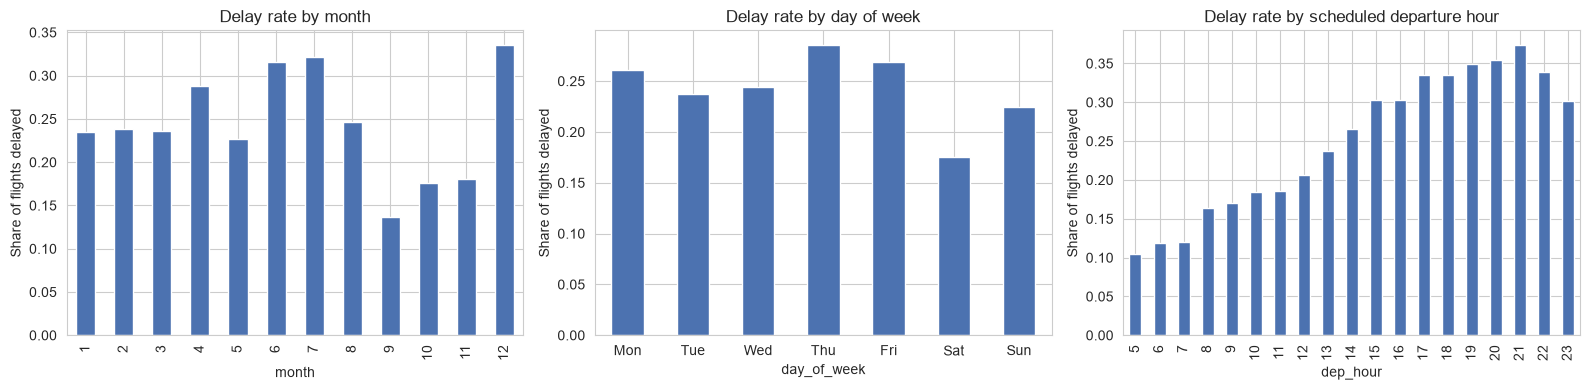

In [7]:
df["day_of_week"] = df["date"].dt.dayofweek   # 0 = Monday
df["dep_hour"] = df["sched_dep_time"] // 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("month")["delayed"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by month")
df.groupby("day_of_week")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[1].set_title("Delay rate by day of week")
df.groupby("dep_hour")["delayed"].mean().plot(kind="bar", ax=axes[2], color="#4C72B0")
axes[2].set_title("Delay rate by scheduled departure hour")
for ax in axes:
    ax.set_ylabel("Share of flights delayed")

plt.tight_layout()
plt.savefig("figures/delay_by_time.png", dpi=150)
plt.show()

- **Month:** December, July and June are the worst months (over 30% delayed); September–November are the calmest (under 20%).
  The delay rate changes a lot over the year, which matters for our date-based split.
- **Day of week:** Saturday is the best day (~18% delayed); Thursday and Monday are the worst.
- **Hour:** the strongest pattern — early morning flights are rarely late, and the delay rate keeps **rising through
  the day** as delays build up across the network.

### 3.3 Delay rate by carrier and origin airport

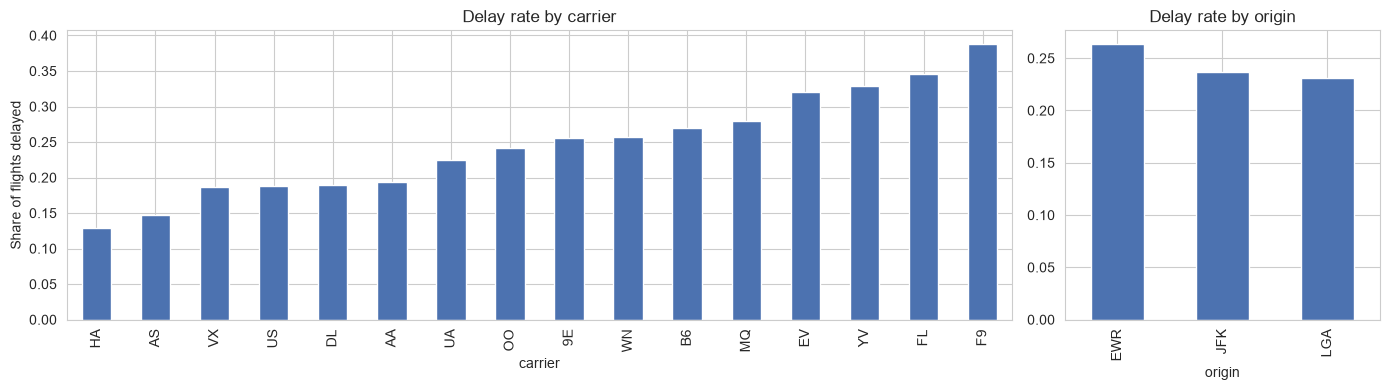

,delay_rate,flights
carrier,,
HA,0.129,342
AS,0.147,709
VX,0.187,5116
US,0.188,19831
DL,0.190,47658
AA,0.194,31947
UA,0.225,57782
OO,0.241,29
9E,0.256,17294


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})

carrier_stats = df.groupby("carrier")["delayed"].agg(["mean", "size"]).sort_values("mean")
carrier_stats["mean"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by carrier")
axes[0].set_ylabel("Share of flights delayed")

df.groupby("origin")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_title("Delay rate by origin")

plt.tight_layout()
plt.savefig("figures/delay_by_carrier_origin.png", dpi=150)
plt.show()

carrier_stats.rename(columns={"mean": "delay_rate", "size": "flights"}).round(3)

- Carriers differ a lot: some small carriers (e.g. FL, F9, EV) are delayed far more often than others (e.g. HA, AS, US).
- **EWR** (Newark) has the highest delay rate of the three airports.

These patterns suggest **carrier, airport and time of day** are useful features.